In [70]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [71]:

import matplotlib.pyplot as plt
import pymc as pm
from pymc.pytensorf import collect_default_updates
import numpy as np
import pytensor
import pytensor.tensor as pt
from scipy.linalg import toeplitz
import prior_generation as pg

# Model 2

With a transpose(mode) function.

In [72]:
PITCH_ALPHABET = list("abcdefghjklmnopqrs")
V = len(PITCH_ALPHABET)
SEQ_LEN = 50
MAX_SHIFT = 3
V_PADDED = V + MAX_SHIFT


In [73]:
def plot_heatmap(matrix):
    plt.imshow(matrix, cmap='binary')
    plt.colorbar()
    plt.show()


In [74]:
def step_fn(x_prev, A):
    p_next = A[x_prev]
    x_tp1 = pm.Categorical.dist(p_next)
    return x_tp1, collect_default_updates([x_tp1])

def scan_dist(x_0, A, length, size):
    sequence, _ = pytensor.scan(
        fn=step_fn,
        outputs_info=[x_0],
        non_sequences=[A],
        n_steps=length - 1,
        strict=True,
    )
    return sequence

coords = {
    "steps": range(SEQ_LEN - 1),
    "full_sequence": range(SEQ_LEN),
}

with pm.Model(coords=coords) as model:
    length = pm.Poisson("length", SEQ_LEN)
    
    nu = pm.Dirichlet("nu", a=np.ones(4))
    m = pm.Categorical("m", p=nu)
    
    
    A_0 = pm.Dirichlet("A_0", a=pg.get_beta())
    A = pm.Deterministic("A_m", pg.transpose_beta(A_0, m))
    ## SHIFT INDEX
    
    pi = pm.Dirichlet("pi", a=pg.get_alpha_m(m))
    x_0 = pm.Categorical("x_0", p=pi) 
    
    steps = pm.CustomDist(
        "x_t+1",
        x_0,
        A,
        length,
        dist=scan_dist,
    )

/var/folders/64/v2j39fj147b5_y9gs8478v2m0000gn/T/ipykernel_69620/2902183851.py:7: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  sequence, _ = pytensor.scan(
/var/folders/64/v2j39fj147b5_y9gs8478v2m0000gn/T/ipykernel_69620/2902183851.py:7: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  sequence, _ = pytensor.scan(


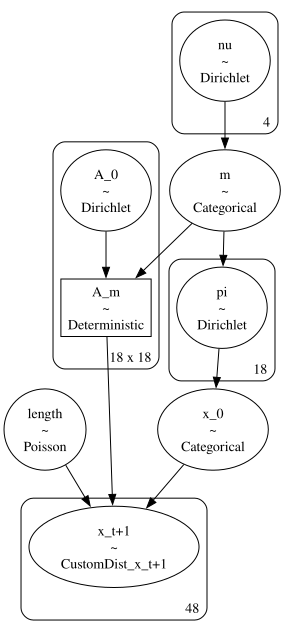

In [75]:
pm.model_to_graphviz(model)

In [79]:
with model:
    prior_samples = pm.sample_prior_predictive(samples=1)

import utils as u
import pandas as pd
pitch_0 = prior_samples.prior["x_0"].to_series()
pitch_series = prior_samples.prior["x_t+1"].to_series()

sequence = pd.concat([pitch_0, pitch_series])

melody = u.to_pitches(sequence, PITCH_ALPHABET)[::-1]
u.to_volpiano(melody)

Sampling: [A_0, length, m, nu, pi, x_0, x_t+1]


In [80]:
prior_samples.prior

<xarray.Dataset> Size: 7kB
Dimensions:      (chain: 1, draw: 1, x_t+1_dim_0: 49, pi_dim_0: 18,
                  nu_dim_0: 4, A_m_dim_0: 18, A_m_dim_1: 18, A_0_dim_0: 18,
                  A_0_dim_1: 18)
Coordinates:
  * chain        (chain) int64 8B 0
  * draw         (draw) int64 8B 0
  * x_t+1_dim_0  (x_t+1_dim_0) int64 392B 0 1 2 3 4 5 6 ... 42 43 44 45 46 47 48
  * pi_dim_0     (pi_dim_0) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
  * nu_dim_0     (nu_dim_0) int64 32B 0 1 2 3
  * A_m_dim_0    (A_m_dim_0) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
  * A_m_dim_1    (A_m_dim_1) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
  * A_0_dim_0    (A_0_dim_0) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
  * A_0_dim_1    (A_0_dim_1) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
Data variables:
    x_0          (chain, draw) int64 8B 5
    length       (chain, draw) int64 8B 50
    m            (chain, draw) int64 8B 2
    x_t+1        (chain, draw, x_t+1_dim_0) int64 392B 6 7 7 10 11 ... 8 6 5 6 8
    pi           (chain, draw, pi_dim_0) float64 144B 5.635e-114 ... 2.071e-18
    nu           (chain, draw, nu_dim_0) float64 32B 0.153 0.4976 0.1491 0.2003
    A_m          (chain, draw, A_m_dim_0, A_m_dim_1) float64 3kB 0.145 ... 0....
    A_0          (chain, draw, A_0_dim_0, A_0_dim_1) float64 3kB 0.03097 ... ...
Attributes:
    created_at:                 2026-03-16T12:47:36.961823+00:00
    arviz_version:              0.23.4
    inference_library:          pymc
    inference_library_version:  5.28.1

In [ ]:
plot_heatmap(prior_samples.prior.A_0.sel(chain=0, draw=0))

In [ ]:
plot_heatmap(prior_samples.prior.A_m.sel(chain=0, draw=0))

In [ ]:
print(prior_samples.prior.A_0.sel(chain=0, draw=0))

In [ ]:
print(prior_samples.prior.A_m.sel(chain=0, draw=0))